In [4]:
# Panji Malik Ibrahim_202431202

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Baca Dataset hasil scraping
df = pd.read_excel('hasil_scraping_books.xlsx')

print("Dataset berhasil dimuat.")
print("Tampilan 5 data teratas:")
df.head()

Dataset berhasil dimuat.
Tampilan 5 data teratas:


,Judul_Buku,Harga_GBP,Rating_Angka
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5


In [5]:
# Panji Malik Ibrahim_202431202

# Buang data kosong pada kolom x (Rating_Angka) dan y (Harga_GBP)
df_clean = df.dropna(subset=['Rating_Angka', 'Harga_GBP'])

# Tentukan nilai x (fitur) dan y (target)
X = df_clean[['Rating_Angka']]  # Fitur (x)
y = df_clean['Harga_GBP']       # Target (y)

# Bagi data latih dan data uji (test_size = 0.2, random_state = 0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("Langkah Selesai!")
print(f"Jumlah data latih (80%): {len(X_train)} baris")
print(f"Jumlah data uji (20%)  : {len(X_test)} baris")

Langkah Selesai!
Jumlah data latih (80%): 240 baris
Jumlah data uji (20%)  : 60 baris


=== HASIL EVALUASI MODEL REGRESI LINEAR ===
Koefisien (b) : 0.3856
Intercept (a) : 33.5329
MSE           : 204.7155
R2 Score      : -0.0229

Persamaan Regresi: Y = 33.5329 + (0.3856) * X
Artinya: Harga_GBP = 33.5329 + (0.3856) * Rating_Angka


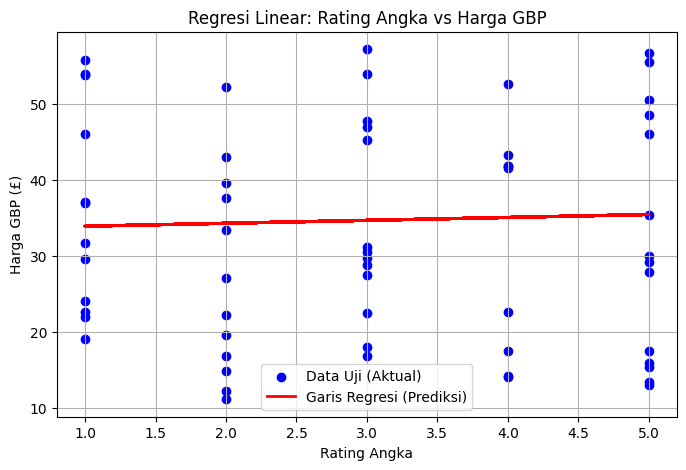

In [6]:
# Panji Malik Ibrahim_202431202

# Buat model LinearRegression
model = LinearRegression()

# Latih model (fit) dengan data latih
model.fit(X_train, y_train)

# Prediksi data uji (predict)
y_pred = model.predict(X_test)

# Evaluasi model (Koefisien, Intercept, MSE, R2 Score)
koefisien = model.coef_[0]
intercept = model.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL REGRESI LINEAR ===")
print(f"Koefisien (b) : {koefisien:.4f}")
print(f"Intercept (a) : {intercept:.4f}")
print(f"MSE           : {mse:.4f}")
print(f"R2 Score      : {r2:.4f}")
print("=" * 43)

# Tulis Persamaan Regresi
print(f"\nPersamaan Regresi: Y = {intercept:.4f} + ({koefisien:.4f}) * X")
print(f"Artinya: Harga_GBP = {intercept:.4f} + ({koefisien:.4f}) * Rating_Angka")

# Visualisasi Grafik Scatter Plot & Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Data Uji (Aktual)')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Garis Regresi (Prediksi)')
plt.title('Regresi Linear: Rating Angka vs Harga GBP')
plt.xlabel('Rating Angka')
plt.ylabel('Harga GBP (£)')
plt.legend()
plt.grid(True)
plt.show()